# Cache-Aware Structured Pruning for Energy-Efficient Deep Learning
## ResNet-18 on CIFAR-10 — Complete End-to-End Experiment

### What this notebook does

This notebook implements the complete experimental pipeline:

1. Check the Python/PyTorch/GPU environment.
2. Download and extract CIFAR-10 automatically.
3. **Automatically detect the real extracted CIFAR-10 directory** (`cifar-10-batches-py` or another valid location).
4. Convert CIFAR-10 one batch at a time to disk-backed NumPy files.
5. Train a CIFAR-adapted ResNet-18 on the GPU.
6. Save checkpoints so a crash/restart does not lose all progress.
7. Measure baseline accuracy, parameters, model size, FLOPs/MACs, latency, GPU memory and **actual GPU energy using NVML** when available.
8. Create a conventional structured-pruning model.
9. Fine-tune and measure it.
10. Perform cache/working-set analysis.
11. Build a cache-aware pruning policy from filter importance + estimated cache pressure.
12. Apply dependency-aware structured pruning.
13. Fine-tune and measure it.
14. Produce a final three-way comparison:
   - Baseline ResNet-18
   - Conventional structured pruning
   - Cache-aware structured pruning

### Important

The notebook uses mini-batches and memory-mapped NumPy arrays. It never intentionally loads all 60,000 CIFAR-10 images onto the GPU at once.

For the first run, keep `SMOKE_TEST = True`. Once the complete pipeline works, set it to `False` for the real experiment.

## 1. Experiment configuration

**What happens in this cell:**  
All paths, batch sizes, epoch counts, pruning ratios, random seed and measurement settings are defined in one place.

If your machine has limited RAM/VRAM, reduce `BATCH_SIZE`.

`SMOKE_TEST=True` runs a short experiment to verify the whole pipeline before committing to a long training run.

In [36]:

from pathlib import Path
import os
import random
import time
import gc
import json
import math
import pickle
import subprocess
import sys

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42

# -----------------------------
# Project directories
# -----------------------------
PROJECT_ROOT = Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data"
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
RESULT_ROOT = PROJECT_ROOT / "results"

DATA_ROOT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
RESULT_ROOT.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Dataset
# -----------------------------
CIFAR_URL = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
CIFAR_ARCHIVE = DATA_ROOT / "cifar-10-python.tar.gz"
MEMMAP_ROOT = DATA_ROOT / "cifar10_memmap"

# -----------------------------
# Training
# -----------------------------
SMOKE_TEST = False

BATCH_SIZE = 128
NUM_WORKERS = 0  # Important for Jupyter/VS Code notebooks: avoids multiprocessing pickling errors

if SMOKE_TEST:
    BASELINE_EPOCHS = 3
    FINETUNE_EPOCHS = 2
    ENERGY_BATCHES = 20
else:
    BASELINE_EPOCHS = 50
    FINETUNE_EPOCHS = 20
    ENERGY_BATCHES = 100

LEARNING_RATE = 0.1
WEIGHT_DECAY = 5e-4
MOMENTUM = 0.9

# Validation split from the original 50,000 training images
VAL_SIZE = 5000

# Conventional pruning target.
# This is the requested fraction of channels before dependency adjustments.
CONVENTIONAL_PRUNING_RATIO = 0.30

# Cache-aware maximum pruning ratio.
CACHE_AWARE_MAX_RATIO = 0.40

# Keep channel counts reasonably hardware friendly.
ROUND_TO = 8

# Number of warmup and timed inference batches
ENERGY_WARMUP_BATCHES = 10

print("Project root:", PROJECT_ROOT)
print("Data root:", DATA_ROOT)
print("Checkpoint root:", CHECKPOINT_ROOT)
print("Result root:", RESULT_ROOT)
print("Smoke test:", SMOKE_TEST)
print("Batch size:", BATCH_SIZE)
print("Baseline epochs:", BASELINE_EPOCHS)
print("Fine-tune epochs:", FINETUNE_EPOCHS)


Project root: /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research
Data root: /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data
Checkpoint root: /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/checkpoints
Result root: /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/results
Smoke test: False
Batch size: 128
Baseline epochs: 50
Fine-tune epochs: 20


## 2. Install/check required Python packages

**What happens in this cell:**  
The notebook checks for the libraries it needs. It installs missing packages into the current Python environment.

The important optional packages are:

- `torch-pruning` — dependency-aware structured pruning.
- `pynvml` — direct NVIDIA GPU power measurements.
- `fvcore` — FLOP/MAC analysis.

If your environment is offline, install these packages manually and rerun the cell.

In [37]:

import importlib.util
import subprocess
import sys

REQUIRED = {
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "PIL": "pillow",
    "torch_pruning": "torch-pruning",
    "pynvml": "nvidia-ml-py",
    "fvcore": "fvcore",
}

missing = []

for module, package in REQUIRED.items():
    if importlib.util.find_spec(module) is None:
        missing.append(package)

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", *missing]
    )
else:
    print("All required packages are already installed.")

print("Dependency check complete.")


All required packages are already installed.
Dependency check complete.


## 3. Import libraries and configure reproducibility

**What happens in this cell:**  
Imports PyTorch, torchvision, NumPy, pandas, plotting tools, NVML and torch-pruning. It also configures deterministic/random seeds where practical.

In [38]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch_pruning as tp

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

try:
    import pynvml
    NVML_IMPORT_OK = True
except Exception:
    NVML_IMPORT_OK = False

try:
    from fvcore.nn import FlopCountAnalysis
    FVCORE_OK = True
except Exception:
    FVCORE_OK = False

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

print("PyTorch:", torch.__version__)
print("Torchvision imported.")
print("Torch-Pruning:", tp.__version__ if hasattr(tp, "__version__") else "installed")
print("FVCore available:", FVCORE_OK)
print("NVML available:", NVML_IMPORT_OK)


PyTorch: 2.12.1+cu130
Torchvision imported.
Torch-Pruning: 1.6.0
FVCore available: True
NVML available: True


## 4. Check GPU and NVML

**What happens in this cell:**  
Confirms whether PyTorch can see the GPU and checks whether NVIDIA Management Library (NVML) can expose power readings.

Energy results are only reported as measured GPU energy when NVML successfully provides power data. The notebook does not invent energy from FLOPs.

> **NVML warning:** If PyTorch prints a `pynvml package is deprecated` warning,
> it is only a warning and does not cause the training failure. The notebook
> can continue; energy measurement still requires NVIDIA NVML support.


In [39]:

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    print("VRAM GB:", round(props.total_memory / (1024**3), 2))
    print("Compute capability:", f"{props.major}.{props.minor}")
else:
    print("WARNING: CUDA is not available. Training will run on CPU.")

NVML_OK = False
NVML_HANDLE = None

if NVML_IMPORT_OK and DEVICE.type == "cuda":
    try:
        pynvml.nvmlInit()
        NVML_HANDLE = pynvml.nvmlDeviceGetHandleByIndex(0)
        NVML_OK = True

        name = pynvml.nvmlDeviceGetName(NVML_HANDLE)
        power_mw = pynvml.nvmlDeviceGetPowerUsage(NVML_HANDLE)

        print("NVML GPU:", name.decode() if isinstance(name, bytes) else name)
        print("Current GPU power (W):", round(power_mw / 1000.0, 2))
        print("NVML power measurement: AVAILABLE")
    except Exception as e:
        NVML_OK = False
        print("NVML power measurement unavailable:", repr(e))
else:
    print("NVML power measurement unavailable.")

print("NVML_OK =", NVML_OK)


Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM GB: 5.64
Compute capability: 8.9
NVML GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Current GPU power (W): 1.6
NVML power measurement: AVAILABLE
NVML_OK = True


## 5. Download and extract CIFAR-10

**What happens in this cell:**  
Downloads the official CIFAR-10 Python archive if it is not already present.

The important fix compared with the earlier notebook is that this cell **does not assume the extracted directory is named `cifar-10-python`**. It searches for the directory containing all six expected CIFAR-10 batch files.

This prevents the `FileNotFoundError` caused by expecting the wrong directory name.

In [40]:

import urllib.request
import tarfile

print("CIFAR-10 archive:", CIFAR_ARCHIVE)

if not CIFAR_ARCHIVE.exists():
    print("Downloading CIFAR-10...")
    urllib.request.urlretrieve(CIFAR_URL, CIFAR_ARCHIVE)
    print("Download complete.")
else:
    print("Archive already exists. No download required.")

print("\nExtracting CIFAR-10...")

with tarfile.open(CIFAR_ARCHIVE, "r:gz") as tar:
    tar.extractall(DATA_ROOT)

print("Extraction completed.")

required_files = [
    "data_batch_1",
    "data_batch_2",
    "data_batch_3",
    "data_batch_4",
    "data_batch_5",
    "test_batch",
]

candidates = []

for path in DATA_ROOT.rglob("data_batch_1"):
    parent = path.parent
    if all((parent / f).exists() for f in required_files):
        candidates.append(parent)

if not candidates:
    print("\nContents under data/:")
    for p in DATA_ROOT.iterdir():
        print(" ", p)

    raise FileNotFoundError(
        "CIFAR-10 files were not found after extraction."
    )

RAW_ROOT = candidates[0]

print("\nCIFAR-10 dataset found at:")
print(RAW_ROOT)

print("\nRequired files:")
for f in required_files:
    print("  ✓", RAW_ROOT / f)

print("\nCIFAR-10 raw dataset is ready.")


CIFAR-10 archive: /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar-10-python.tar.gz
Archive already exists. No download required.

Extracting CIFAR-10...
Extraction completed.

CIFAR-10 dataset found at:
/home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar-10-batches-py

Required files:
  ✓ /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar-10-batches-py/data_batch_1
  ✓ /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar-10-batches-py/data_batch_2
  ✓ /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar-10-batches-py/data_batch_3
  ✓ /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar-10-batches-py/data_batch_4
  ✓ /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar-10-batches-py/data_batch_5
  ✓ /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar-10-batches-py/test_batch

CIFAR-10 raw 

## 6. Convert CIFAR-10 one batch at a time to memory-mapped NumPy files

**What happens in this cell:**  
CIFAR-10 contains five 10,000-image training pickle files and one 10,000-image test file.

This cell processes **one pickle at a time**, saves it to `.npy`, deletes the temporary arrays and runs garbage collection.

The resulting `.npy` files are later opened with `mmap_mode="r"`, so the DataLoader can read samples from disk without loading the complete dataset into RAM.

In [41]:

MEMMAP_ROOT.mkdir(parents=True, exist_ok=True)

def read_cifar_pickle(path):
    with open(path, "rb") as f:
        obj = pickle.load(f, encoding="bytes")

    data = np.asarray(obj[b"data"], dtype=np.uint8)
    labels = np.asarray(obj[b"labels"], dtype=np.int64)

    # CIFAR pickle layout: N x (3*32*32)
    data = data.reshape(-1, 3, 32, 32)

    # Convert to N x 32 x 32 x 3 for PIL
    data = np.transpose(data, (0, 2, 3, 1))

    return data, labels

def convert_one_batch(pkl_path, data_out, labels_out):
    if data_out.exists() and labels_out.exists():
        print("Already converted:", pkl_path.name)
        return

    print("\nReading:", pkl_path)

    data, labels = read_cifar_pickle(pkl_path)

    print("Images:", data.shape)
    print("Labels:", labels.shape)

    np.save(data_out, data, allow_pickle=False)
    np.save(labels_out, labels, allow_pickle=False)

    del data
    del labels
    gc.collect()

    print("Saved and RAM released.")

for i in range(1, 6):
    convert_one_batch(
        RAW_ROOT / f"data_batch_{i}",
        MEMMAP_ROOT / f"train_{i}_data.npy",
        MEMMAP_ROOT / f"train_{i}_labels.npy",
    )

convert_one_batch(
    RAW_ROOT / "test_batch",
    MEMMAP_ROOT / "test_data.npy",
    MEMMAP_ROOT / "test_labels.npy",
)

print("\nConversion complete.")
print("Memory-mapped files:", MEMMAP_ROOT)


Already converted: data_batch_1
Already converted: data_batch_2
Already converted: data_batch_3
Already converted: data_batch_4
Already converted: data_batch_5
Already converted: test_batch

Conversion complete.
Memory-mapped files: /home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar10_memmap


## 7. Define the memory-mapped CIFAR-10 Dataset

**What happens in this cell:**  
Defines a PyTorch `Dataset` that uses `np.load(..., mmap_mode="r")`.

Only the requested image is read when `__getitem__` is called. The complete 50,000-image training set is therefore not loaded into RAM.

In [42]:

class CIFAR10MemmapDataset(Dataset):
    def __init__(self, data_files, label_files, transform=None):
        self.data_files = [Path(x) for x in data_files]
        self.label_files = [Path(x) for x in label_files]
        self.transform = transform

        self.data = [
            np.load(path, mmap_mode="r")
            for path in self.data_files
        ]

        self.labels = [
            np.load(path, mmap_mode="r")
            for path in self.label_files
        ]

        self.lengths = [len(x) for x in self.labels]
        self.cumulative = np.cumsum(self.lengths)
        self.total_length = int(self.cumulative[-1])

    def __len__(self):
        return self.total_length

    def __getitem__(self, index):
        batch_idx = int(
            np.searchsorted(
                self.cumulative,
                index,
                side="right"
            )
        )

        if batch_idx == 0:
            local_idx = index
        else:
            local_idx = index - self.cumulative[batch_idx - 1]

        image = self.data[batch_idx][local_idx]
        label = int(self.labels[batch_idx][local_idx])

        image = Image.fromarray(image)

        if self.transform is not None:
            image = self.transform(image)

        return image, label

print("Memory-mapped Dataset class created.")


Memory-mapped Dataset class created.


## 8. Create train/validation/test datasets and DataLoaders

**What happens in this cell:**  
Creates a 45,000-image training set and 5,000-image validation set from the five CIFAR-10 training batches, plus the official 10,000-image test set.

The DataLoader transfers only each mini-batch to the GPU.

> **Notebook multiprocessing note:** `NUM_WORKERS` is intentionally set to `0`.
> The dataset class is defined inside this notebook, and Python 3.14/Jupyter
> multiprocessing can try to pickle that class in a separate worker process,
> producing errors such as `__main__ has no attribute CIFAR10IndexedMemmapDataset`.
> Using `num_workers=0` keeps loading in the notebook process and still protects
> RAM because the images are read from NumPy memory-mapped files on disk.


In [43]:

# CIFAR-10 normalization
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

# Use the first 5,000 samples as validation.
# Training uses the remaining 45,000.
ALL_TRAIN_DATA = [
    MEMMAP_ROOT / f"train_{i}_data.npy"
    for i in range(1, 6)
]

ALL_TRAIN_LABELS = [
    MEMMAP_ROOT / f"train_{i}_labels.npy"
    for i in range(1, 6)
]

class CIFAR10IndexedMemmapDataset(Dataset):
    """
    Dataset over multiple memory-mapped files with an optional
    global index range.
    """
    def __init__(self, data_files, label_files, start=0, end=None, transform=None):
        self.data = [np.load(Path(p), mmap_mode="r") for p in data_files]
        self.labels = [np.load(Path(p), mmap_mode="r") for p in label_files]
        self.transform = transform

        self.lengths = [len(x) for x in self.labels]
        self.cumulative = np.cumsum(self.lengths)
        self.total = int(self.cumulative[-1])

        self.start = int(start)
        self.end = self.total if end is None else int(end)

        if not (0 <= self.start < self.end <= self.total):
            raise ValueError("Invalid dataset range.")

    def __len__(self):
        return self.end - self.start

    def _get_global(self, global_index):
        batch_idx = int(
            np.searchsorted(
                self.cumulative,
                global_index,
                side="right"
            )
        )

        if batch_idx == 0:
            local_idx = global_index
        else:
            local_idx = global_index - self.cumulative[batch_idx - 1]

        return batch_idx, local_idx

    def __getitem__(self, idx):
        global_index = self.start + idx
        batch_idx, local_idx = self._get_global(global_index)

        image = self.data[batch_idx][local_idx]
        label = int(self.labels[batch_idx][local_idx])

        image = Image.fromarray(image)

        if self.transform:
            image = self.transform(image)

        return image, label

train_dataset = CIFAR10IndexedMemmapDataset(
    ALL_TRAIN_DATA,
    ALL_TRAIN_LABELS,
    start=VAL_SIZE,
    end=50000,
    transform=train_transform,
)

val_dataset = CIFAR10IndexedMemmapDataset(
    ALL_TRAIN_DATA,
    ALL_TRAIN_LABELS,
    start=0,
    end=VAL_SIZE,
    transform=eval_transform,
)

test_dataset = CIFAR10MemmapDataset(
    [MEMMAP_ROOT / "test_data.npy"],
    [MEMMAP_ROOT / "test_labels.npy"],
    transform=eval_transform,
)

loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    drop_last=True,
    **loader_kwargs,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_kwargs,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_kwargs,
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Batch size:", BATCH_SIZE)


Training images: 45000
Validation images: 5000
Test images: 10000
Batch size: 128


## 9. Define a CIFAR-adapted ResNet-18

**What happens in this cell:**  
Uses torchvision's ResNet-18 structure but changes the first convolution for CIFAR-10's 32×32 images and removes the initial ImageNet max-pooling operation.

The final classifier outputs 10 classes.

In [44]:

from torchvision.models.resnet import ResNet, BasicBlock

class CIFARResNet18(ResNet):
    def __init__(self, num_classes=10):
        super().__init__(
            block=BasicBlock,
            layers=[2, 2, 2, 2],
            num_classes=num_classes,
        )

        # CIFAR-10: 32x32 images
        self.conv1 = nn.Conv2d(
            3, 64,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False,
        )

        # No ImageNet 7x7 pooling for CIFAR
        self.maxpool = nn.Identity()

def build_model():
    return CIFARResNet18(num_classes=10).to(DEVICE)

model = build_model()

dummy = torch.randn(
    2, 3, 32, 32,
    device=DEVICE
)

with torch.no_grad():
    out = model(dummy)

print(model)
print("Output shape:", tuple(out.shape))


CIFARResNet18(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): 

## 10. General metric utilities

**What happens in this cell:**  
Defines functions for parameter count, model size, accuracy and MAC/FLOP analysis.

FLOPs are a computational metric. They are **not treated as measured energy**.

In [45]:

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

def trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

def model_size_mb(model):
    total_bytes = 0
    for p in model.parameters():
        total_bytes += p.numel() * p.element_size()

    for b in model.buffers():
        total_bytes += b.numel() * b.element_size()

    return total_bytes / (1024 ** 2)

def calculate_flops(model):
    if not FVCORE_OK:
        return float("nan")

    was_training = model.training
    model.eval()

    example = torch.randn(
        1, 3, 32, 32,
        device=DEVICE
    )

    try:
        analysis = FlopCountAnalysis(model, example)
        flops = float(analysis.total())
    except Exception as e:
        print("FLOP analysis failed:", repr(e))
        flops = float("nan")

    if was_training:
        model.train()

    return flops

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(
            DEVICE,
            non_blocking=True
        )
        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        total += images.size(0)

    return (
        total_loss / total,
        100.0 * correct / total
    )

print("Metric utilities ready.")


Metric utilities ready.


## 11. Training utilities with checkpoint/resume support

**What happens in this cell:**  
Creates the training loop, cosine learning-rate schedule and checkpoint system.

A checkpoint is saved whenever validation accuracy improves. If the kernel crashes, the notebook can load the checkpoint and continue instead of losing all previous training.

In [46]:

criterion = nn.CrossEntropyLoss()

try:
    AMP_ENABLED = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED
    )
except Exception:
    AMP_ENABLED = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED
    )

def make_optimizer(model, lr=LEARNING_RATE):
    return optim.SGD(
        model.parameters(),
        lr=lr,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
        nesterov=True,
    )

def make_scheduler(optimizer, epochs):
    return optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

def train_one_epoch(model, loader, optimizer):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    start = time.perf_counter()

    for images, labels in loader:
        images = images.to(
            DEVICE,
            non_blocking=True
        )
        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        if AMP_ENABLED:
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        else:
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        total += images.size(0)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    return (
        running_loss / total,
        100.0 * correct / total,
        elapsed,
    )

def save_checkpoint(path, model, optimizer, scheduler, epoch, best_val):
    torch.save(
        {
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "best_val": best_val,
        },
        path,
    )

def load_checkpoint(path, model, optimizer=None, scheduler=None):
    checkpoint = torch.load(
        path,
        map_location=DEVICE,
    )

    model.load_state_dict(checkpoint["model"])

    if optimizer is not None:
        optimizer.load_state_dict(checkpoint["optimizer"])

    if scheduler is not None:
        scheduler.load_state_dict(checkpoint["scheduler"])

    return (
        checkpoint["epoch"],
        checkpoint["best_val"]
    )

print("Training utilities ready.")


Training utilities ready.


## 12. Train the baseline ResNet-18

**What happens in this cell:**  
Trains the unpruned ResNet-18 using CIFAR-10.

The baseline is the control model against which both pruning methods are compared.

The checkpoint is saved to:

`checkpoints/baseline_resnet18_cifar10.pt`

In [47]:

BASELINE_CKPT = CHECKPOINT_ROOT / "baseline_resnet18_cifar10.pt"
BASELINE_HISTORY = RESULT_ROOT / "baseline_history.csv"

baseline = build_model()
baseline_optimizer = make_optimizer(baseline)
baseline_scheduler = make_scheduler(
    baseline_optimizer,
    BASELINE_EPOCHS
)

start_epoch = 1
best_val = -1.0
history = []

if BASELINE_CKPT.exists():
    print("Existing baseline checkpoint found.")
    answer = input(
        "Resume baseline training from checkpoint? [y/N]: "
    ).strip().lower()

    if answer == "y":
        last_epoch, best_val = load_checkpoint(
            BASELINE_CKPT,
            baseline,
            baseline_optimizer,
            baseline_scheduler,
        )
        start_epoch = last_epoch + 1
        print("Resuming from epoch", start_epoch)

for epoch in range(start_epoch, BASELINE_EPOCHS + 1):

    train_loss, train_acc, epoch_time = train_one_epoch(
        baseline,
        train_loader,
        baseline_optimizer,
    )

    val_loss, val_acc = evaluate(
        baseline,
        val_loader,
        criterion,
    )

    baseline_scheduler.step()

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "epoch_time_sec": epoch_time,
        "lr": baseline_optimizer.param_groups[0]["lr"],
    }

    history.append(row)

    if val_acc > best_val:
        best_val = val_acc

        save_checkpoint(
            BASELINE_CKPT,
            baseline,
            baseline_optimizer,
            baseline_scheduler,
            epoch,
            best_val,
        )

    print(
        f"Epoch {epoch:03d}/{BASELINE_EPOCHS} | "
        f"train_acc={train_acc:.2f}% | "
        f"val_acc={val_acc:.2f}% | "
        f"time={epoch_time:.1f}s | "
        f"best={best_val:.2f}%"
    )

baseline_history_df = pd.DataFrame(history)

if len(baseline_history_df):
    baseline_history_df.to_csv(
        BASELINE_HISTORY,
        index=False,
    )

# Always load the best checkpoint before evaluation.
if BASELINE_CKPT.exists():
    load_checkpoint(
        BASELINE_CKPT,
        baseline,
    )

print("\nBest validation accuracy:", best_val)
print("Baseline checkpoint:", BASELINE_CKPT)


Existing baseline checkpoint found.
Epoch 001/50 | train_acc=23.48% | val_acc=35.70% | time=20.2s | best=35.70%
Epoch 002/50 | train_acc=40.66% | val_acc=47.74% | time=20.1s | best=47.74%
Epoch 003/50 | train_acc=52.21% | val_acc=55.42% | time=20.0s | best=55.42%
Epoch 004/50 | train_acc=61.77% | val_acc=65.70% | time=20.0s | best=65.70%
Epoch 005/50 | train_acc=68.25% | val_acc=66.80% | time=19.9s | best=66.80%
Epoch 006/50 | train_acc=73.59% | val_acc=70.52% | time=20.0s | best=70.52%
Epoch 007/50 | train_acc=77.21% | val_acc=75.22% | time=20.0s | best=75.22%
Epoch 008/50 | train_acc=79.42% | val_acc=79.82% | time=20.1s | best=79.82%
Epoch 009/50 | train_acc=81.10% | val_acc=78.26% | time=20.0s | best=79.82%
Epoch 010/50 | train_acc=82.66% | val_acc=77.72% | time=20.0s | best=79.82%
Epoch 011/50 | train_acc=83.26% | val_acc=80.52% | time=20.0s | best=80.52%
Epoch 012/50 | train_acc=84.55% | val_acc=83.54% | time=20.0s | best=83.54%
Epoch 013/50 | train_acc=84.96% | val_acc=81.60% | t

## 13. Baseline test-set evaluation

**What happens in this cell:**  
Loads the best baseline checkpoint and evaluates it on the untouched CIFAR-10 test set.

In [48]:

baseline_test_loss, baseline_test_acc = evaluate(
    baseline,
    test_loader,
    criterion,
)

print("Baseline test loss:", baseline_test_loss)
print("Baseline test accuracy:", f"{baseline_test_acc:.2f}%")


Baseline test loss: 0.2339860767364502
Baseline test accuracy: 93.60%


## 14. GPU latency and memory measurement

**What happens in this cell:**  
Measures synchronized GPU inference latency and peak allocated GPU memory.

The test is repeated for multiple batches so that a single CUDA startup event does not dominate the result.

In [49]:

@torch.no_grad()
def measure_latency_and_memory(
    model,
    loader,
    warmup_batches=ENERGY_WARMUP_BATCHES,
    timed_batches=ENERGY_BATCHES,
):
    model.eval()

    iterator = iter(loader)

    # Warm-up
    for _ in range(warmup_batches):
        try:
            images, _ = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            images, _ = next(iterator)

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        _ = model(images)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    times = []
    processed_images = 0

    for _ in range(timed_batches):

        try:
            images, _ = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            images, _ = next(iterator)

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        _ = model(images)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        times.append(elapsed)
        processed_images += images.size(0)

    latency_sec = float(np.mean(times))
    latency_ms = latency_sec * 1000.0

    peak_memory_mb = float("nan")

    if DEVICE.type == "cuda":
        peak_memory_mb = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )

    return {
        "latency_batch_ms": latency_ms,
        "latency_image_ms": (
            latency_ms / BATCH_SIZE
        ),
        "peak_gpu_memory_mb": peak_memory_mb,
        "timed_batches": len(times),
        "processed_images": processed_images,
    }

baseline_latency = measure_latency_and_memory(
    baseline,
    test_loader,
)

baseline_latency


{'latency_batch_ms': 22.531269999890355,
 'latency_image_ms': 0.1760255468741434,
 'peak_gpu_memory_mb': 596.7685546875,
 'timed_batches': 100,
 'processed_images': 12688}

## 15. Actual GPU energy measurement with NVML

**What happens in this cell:**  
Reads GPU power from NVML while repeated inference is running.

Energy is calculated as:

`Energy (J) = average power (W) × elapsed time (s)`

and is also reported per image.

This is **measured GPU energy**, not an estimate from FLOPs.

If NVML is unavailable, the result is explicitly marked as unavailable instead of being fabricated.

In [50]:

@torch.no_grad()
def measure_gpu_energy(
    model,
    loader,
    warmup_batches=ENERGY_WARMUP_BATCHES,
    timed_batches=ENERGY_BATCHES,
    sample_interval=0.02,
):
    model.eval()

    if not NVML_OK:
        return {
            "energy_available": False,
            "avg_gpu_power_w": float("nan"),
            "energy_j": float("nan"),
            "energy_per_batch_j": float("nan"),
            "energy_per_image_j": float("nan"),
            "energy_per_image_mj": float("nan"),
            "measurement_time_sec": float("nan"),
        }

    iterator = iter(loader)

    # Warmup
    for _ in range(warmup_batches):
        try:
            images, _ = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            images, _ = next(iterator)

        images = images.to(
            DEVICE,
            non_blocking=True
        )
        _ = model(images)

    torch.cuda.synchronize()

    powers_w = []
    total_images = 0

    start_time = time.perf_counter()

    for _ in range(timed_batches):

        try:
            images, _ = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            images, _ = next(iterator)

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        torch.cuda.synchronize()

        # Read power immediately before inference
        try:
            power_w = (
                pynvml.nvmlDeviceGetPowerUsage(
                    NVML_HANDLE
                ) / 1000.0
            )
            powers_w.append(power_w)
        except Exception:
            pass

        _ = model(images)

        torch.cuda.synchronize()

        total_images += images.size(0)

        # Give NVML a chance to provide another sample.
        time.sleep(sample_interval)

    elapsed = time.perf_counter() - start_time

    if not powers_w or elapsed <= 0:
        return {
            "energy_available": False,
            "avg_gpu_power_w": float("nan"),
            "energy_j": float("nan"),
            "energy_per_batch_j": float("nan"),
            "energy_per_image_j": float("nan"),
            "energy_per_image_mj": float("nan"),
            "measurement_time_sec": elapsed,
        }

    avg_power = float(np.mean(powers_w))
    energy_j = avg_power * elapsed

    return {
        "energy_available": True,
        "avg_gpu_power_w": avg_power,
        "energy_j": energy_j,
        "energy_per_batch_j": energy_j / max(timed_batches, 1),
        "energy_per_image_j": energy_j / max(total_images, 1),
        "energy_per_image_mj": (
            1000.0 * energy_j / max(total_images, 1)
        ),
        "measurement_time_sec": elapsed,
    }

baseline_energy = measure_gpu_energy(
    baseline,
    test_loader,
)

print(pd.Series(baseline_energy))


energy_available              True
avg_gpu_power_w           39.87664
energy_j                224.422691
energy_per_batch_j        2.244227
energy_per_image_j        0.017688
energy_per_image_mj      17.687791
measurement_time_sec      5.627924
dtype: object


## 16. Build the baseline metric record

**What happens in this cell:**  
Combines accuracy, parameters, model size, FLOPs, latency, GPU memory and measured energy into one row.

In [51]:

baseline_metrics = {
    "model": "Baseline ResNet-18",
    "test_accuracy_percent": baseline_test_acc,
    "parameters": count_parameters(baseline),
    "trainable_parameters": trainable_parameters(baseline),
    "model_size_mb": model_size_mb(baseline),
    "flops": calculate_flops(baseline),
    **baseline_latency,
    **baseline_energy,
}

baseline_metrics_df = pd.DataFrame([baseline_metrics])
baseline_metrics_df.to_csv(
    RESULT_ROOT / "baseline_metrics.csv",
    index=False,
)

baseline_metrics_df.T


Unsupported operator aten::add_ encountered 8 time(s)


,0
model,Baseline ResNet-18
test_accuracy_percent,93.6
parameters,11173962
trainable_parameters,11173962
model_size_mb,42.662056
flops,556659712.0
latency_batch_ms,22.53127
latency_image_ms,0.176026
peak_gpu_memory_mb,596.768555
timed_batches,100


## 17. Save a clean copy of the baseline model

**What happens in this cell:**  
Stores the trained baseline weights separately. This is important because pruning modifies a model in-place and we need the original baseline for later comparisons.

In [52]:

BASELINE_WEIGHTS = CHECKPOINT_ROOT / "baseline_best_weights.pt"

torch.save(
    baseline.state_dict(),
    BASELINE_WEIGHTS,
)

print("Saved baseline weights to:")
print(BASELINE_WEIGHTS)


Saved baseline weights to:
/home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/checkpoints/baseline_best_weights.pt


## 18. Prepare a conventional structured-pruning model

**What happens in this cell:**  
Creates a fresh ResNet-18 and loads the trained baseline weights.

This model is the control pruning method. It uses magnitude-based channel importance rather than the cache-aware policy.

In [53]:

def fresh_baseline_model():
    m = build_model()
    m.load_state_dict(
        torch.load(
            BASELINE_WEIGHTS,
            map_location=DEVICE,
        )
    )
    return m

conventional_model = fresh_baseline_model()

print(
    "Parameters before conventional pruning:",
    count_parameters(conventional_model)
)


Parameters before conventional pruning: 11173962


## 19. Conventional dependency-aware structured pruning

**What happens in this cell:**  
Uses torch-pruning's dependency graph so that channels removed from a convolution are propagated to dependent layers.

This is important for ResNet because residual connections create structural dependencies.

The conventional method uses a uniform target pruning ratio and magnitude-based importance.

In [54]:

def get_ignored_layers(model):
    ignored = []

    # Never prune the classifier output channels.
    ignored.append(model.fc)

    # Never prune the first input convolution.
    ignored.append(model.conv1)

    return ignored

def apply_conventional_pruning(model, ratio=0.30):
    model.eval()

    example_inputs = torch.randn(
        1, 3, 32, 32,
        device=DEVICE
    )

    importance = tp.importance.MagnitudeImportance(
        p=2,
        group_reduction="mean",
    )

    ignored_layers = get_ignored_layers(model)

    pruner = tp.pruner.MetaPruner(
        model,
        example_inputs=example_inputs,
        importance=importance,
        global_pruning=True,
        pruning_ratio=ratio,
        ignored_layers=ignored_layers,
        round_to=ROUND_TO,
    )

    pruner.step()

    # Verify the graph after surgery.
    with torch.no_grad():
        output = model(example_inputs)

    print("Conventional pruning forward pass:", tuple(output.shape))

    return model

conventional_model = apply_conventional_pruning(
    conventional_model,
    CONVENTIONAL_PRUNING_RATIO,
)

print(
    "Parameters after conventional pruning:",
    count_parameters(conventional_model)
)


Conventional pruning forward pass: (1, 10)
Parameters after conventional pruning: 5147162


## 20. Measure conventional-pruning structural changes

**What happens in this cell:**  
Records the actual parameter and FLOP reduction. The final reduction can differ from the requested pruning ratio because dependency-aware pruning has to respect residual graph constraints.

In [55]:

conventional_before_params = baseline_metrics["parameters"]
conventional_after_params = count_parameters(conventional_model)

conventional_before_flops = baseline_metrics["flops"]
conventional_after_flops = calculate_flops(conventional_model)

print("Baseline parameters:", conventional_before_params)
print("Pruned parameters:", conventional_after_params)

print(
    "Parameter reduction (%):",
    100.0 * (
        conventional_before_params -
        conventional_after_params
    ) / conventional_before_params
)

print("Baseline FLOPs:", conventional_before_flops)
print("Pruned FLOPs:", conventional_after_flops)

if np.isfinite(conventional_before_flops) and np.isfinite(conventional_after_flops):
    print(
        "FLOP reduction (%):",
        100.0 * (
            conventional_before_flops -
            conventional_after_flops
        ) / conventional_before_flops
    )


Unsupported operator aten::add_ encountered 8 time(s)


Baseline parameters: 11173962
Pruned parameters: 5147162
Parameter reduction (%): 53.93610610095148
Baseline FLOPs: 556659712.0
Pruned FLOPs: 286701216.0
FLOP reduction (%): 48.49614408595821


## 21. Fine-tune the conventional pruned model

**What happens in this cell:**  
Fine-tunes the structurally pruned network so that it can recover some of the accuracy lost during pruning.

In [56]:

CONVENTIONAL_CKPT = CHECKPOINT_ROOT / "conventional_pruned_best.pt"

conv_optimizer = make_optimizer(
    conventional_model,
    lr=LEARNING_RATE * 0.1,
)
conv_scheduler = make_scheduler(
    conv_optimizer,
    FINETUNE_EPOCHS,
)

best_conv_val = -1.0
conv_history = []

for epoch in range(1, FINETUNE_EPOCHS + 1):

    train_loss, train_acc, epoch_time = train_one_epoch(
        conventional_model,
        train_loader,
        conv_optimizer,
    )

    val_loss, val_acc = evaluate(
        conventional_model,
        val_loader,
        criterion,
    )

    conv_scheduler.step()

    conv_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "epoch_time_sec": epoch_time,
    })

    if val_acc > best_conv_val:
        best_conv_val = val_acc

        torch.save(
            conventional_model.state_dict(),
            CONVENTIONAL_CKPT,
        )

    print(
        f"Pruned epoch {epoch:03d}/{FINETUNE_EPOCHS} | "
        f"train_acc={train_acc:.2f}% | "
        f"val_acc={val_acc:.2f}% | "
        f"time={epoch_time:.1f}s"
    )

if CONVENTIONAL_CKPT.exists():
    conventional_model.load_state_dict(
        torch.load(
            CONVENTIONAL_CKPT,
            map_location=DEVICE,
        )
    )

pd.DataFrame(conv_history).to_csv(
    RESULT_ROOT / "conventional_pruned_history.csv",
    index=False,
)

print("Best conventional validation accuracy:", best_conv_val)


Pruned epoch 001/20 | train_acc=98.18% | val_acc=92.12% | time=18.5s
Pruned epoch 002/20 | train_acc=98.02% | val_acc=93.00% | time=15.1s
Pruned epoch 003/20 | train_acc=98.03% | val_acc=93.14% | time=15.2s
Pruned epoch 004/20 | train_acc=98.05% | val_acc=91.74% | time=15.2s
Pruned epoch 005/20 | train_acc=98.37% | val_acc=91.90% | time=15.1s
Pruned epoch 006/20 | train_acc=98.43% | val_acc=92.64% | time=15.2s
Pruned epoch 007/20 | train_acc=98.50% | val_acc=93.00% | time=15.2s
Pruned epoch 008/20 | train_acc=98.77% | val_acc=92.84% | time=15.1s
Pruned epoch 009/20 | train_acc=99.08% | val_acc=92.96% | time=15.2s
Pruned epoch 010/20 | train_acc=99.20% | val_acc=93.14% | time=15.2s
Pruned epoch 011/20 | train_acc=99.45% | val_acc=93.88% | time=15.2s
Pruned epoch 012/20 | train_acc=99.65% | val_acc=93.78% | time=15.2s
Pruned epoch 013/20 | train_acc=99.75% | val_acc=94.02% | time=15.2s
Pruned epoch 014/20 | train_acc=99.77% | val_acc=94.34% | time=15.2s
Pruned epoch 015/20 | train_acc=99

## 22. Evaluate and measure conventional pruning

**What happens in this cell:**  
Measures the conventional pruned model on the test set and records latency, memory and actual GPU energy.

In [57]:

conv_test_loss, conv_test_acc = evaluate(
    conventional_model,
    test_loader,
    criterion,
)

conv_latency = measure_latency_and_memory(
    conventional_model,
    test_loader,
)

conv_energy = measure_gpu_energy(
    conventional_model,
    test_loader,
)

conventional_metrics = {
    "model": "Conventional structured pruning",
    "test_accuracy_percent": conv_test_acc,
    "parameters": count_parameters(conventional_model),
    "trainable_parameters": trainable_parameters(conventional_model),
    "model_size_mb": model_size_mb(conventional_model),
    "flops": calculate_flops(conventional_model),
    **conv_latency,
    **conv_energy,
}

pd.DataFrame([conventional_metrics]).T


Unsupported operator aten::add_ encountered 8 time(s)


,0
model,Conventional structured pruning
test_accuracy_percent,93.76
parameters,5147162
trainable_parameters,5147162
model_size_mb,19.660347
flops,286701216.0
latency_batch_ms,15.120854
latency_image_ms,0.118132
peak_gpu_memory_mb,653.813965
timed_batches,100


## 23. Cache/working-set analysis

**What happens in this cell:**  
This is the first part of the proposed cache-aware method.

For each convolutional layer we estimate a simple layer working set from:

- weight tensor size
- output activation size

The analysis is deliberately transparent: it is an **estimated cache-pressure model**, not a replacement for hardware performance counters.

For direct L2 hit/miss evidence, a later Nsight Compute experiment should be used.

In [58]:

def convolution_working_set_report(model, batch_size=1):
    rows = []

    hooks = []

    def make_hook(name, module):
        def hook(module, inputs, output):
            if isinstance(output, tuple):
                out = output[0]
            else:
                out = output

            if not torch.is_tensor(out):
                return

            weight_bytes = (
                module.weight.numel() *
                module.weight.element_size()
            )

            activation_bytes = (
                out.numel() *
                out.element_size()
            )

            rows.append({
                "layer": name,
                "out_channels": module.out_channels,
                "in_channels": module.in_channels,
                "kernel_h": module.kernel_size[0],
                "kernel_w": module.kernel_size[1],
                "weight_mb": weight_bytes / (1024**2),
                "activation_mb": activation_bytes / (1024**2),
                "working_set_mb": (
                    weight_bytes + activation_bytes
                ) / (1024**2),
            })

        return hook

    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            hooks.append(
                module.register_forward_hook(
                    make_hook(name, module)
                )
            )

    model.eval()

    x = torch.randn(
        batch_size,
        3,
        32,
        32,
        device=DEVICE,
    )

    with torch.no_grad():
        _ = model(x)

    for h in hooks:
        h.remove()

    return pd.DataFrame(rows)

cache_report = convolution_working_set_report(
    baseline,
    batch_size=1,
)

# Save for the research record
cache_report.to_csv(
    RESULT_ROOT / "baseline_cache_working_sets.csv",
    index=False,
)

print(cache_report.to_string(index=False))


                layer  out_channels  in_channels  kernel_h  kernel_w  weight_mb  activation_mb  working_set_mb
                conv1            64            3         3         3   0.006592        0.25000        0.256592
       layer1.0.conv1            64           64         3         3   0.140625        0.25000        0.390625
       layer1.0.conv2            64           64         3         3   0.140625        0.25000        0.390625
       layer1.1.conv1            64           64         3         3   0.140625        0.25000        0.390625
       layer1.1.conv2            64           64         3         3   0.140625        0.25000        0.390625
       layer2.0.conv1           128           64         3         3   0.281250        0.12500        0.406250
       layer2.0.conv2           128          128         3         3   0.562500        0.12500        0.687500
layer2.0.downsample.0           128           64         1         1   0.031250        0.12500        0.156250
 

## 24. Determine the target cache size

**What happens in this cell:**  
Attempts to obtain the GPU's L2 cache size from PyTorch device properties.

If the installed PyTorch version does not expose L2 size, the notebook uses a configurable fallback. The fallback is clearly marked as an assumption.

This is an **estimated working-set model**; it should not be described as direct cache-counter measurement.

In [59]:

def get_l2_cache_mb():
    if DEVICE.type != "cuda":
        return float("nan"), "CPU"

    props = torch.cuda.get_device_properties(0)

    # Newer PyTorch builds may expose l2_cache_size.
    if hasattr(props, "l2_cache_size"):
        value = getattr(props, "l2_cache_size")
        if value:
            return value / (1024**2), "PyTorch device property"

    # Some versions expose L2 cache through an internal attribute.
    for attr in ["L2_cache_size", "l2_cache_size"]:
        if hasattr(props, attr):
            value = getattr(props, attr)
            if value:
                return value / (1024**2), f"PyTorch property: {attr}"

    return 4.0, "fallback assumption"

L2_CACHE_MB, L2_SOURCE = get_l2_cache_mb()

print("Estimated/known L2 cache size (MB):", L2_CACHE_MB)
print("Source:", L2_SOURCE)


Estimated/known L2 cache size (MB): 24.0
Source: PyTorch property: L2_cache_size


## 25. Build the cache-aware pruning policy

**What happens in this cell:**  
Combines two signals:

1. **Filter importance** — channels with low magnitude are easier candidates for removal.
2. **Cache pressure** — layers with larger working sets relative to the target cache are given more pruning pressure.

The resulting policy assigns a layer-specific pruning ratio.

This is the experimental research component. The exact weighting can be tuned in later experiments.

In [60]:

def layer_importance_and_cache_pressure(model, cache_df):
    rows = []

    for name, module in model.named_modules():
        if not isinstance(module, nn.Conv2d):
            continue

        # Do not prune the first convolution.
        if name == "conv1":
            continue

        weight = module.weight.detach()

        # Per-output-channel L2 magnitude
        importance = weight.flatten(1).norm(p=2, dim=1)

        mean_importance = float(
            importance.mean().item()
        )

        if name in set(cache_df["layer"]):
            ws = float(
                cache_df.loc[
                    cache_df["layer"] == name,
                    "working_set_mb"
                ].iloc[0]
            )
        else:
            ws = 0.0

        pressure = ws / max(L2_CACHE_MB, 1e-9)

        rows.append({
            "layer": name,
            "mean_filter_importance": mean_importance,
            "working_set_mb": ws,
            "cache_pressure": pressure,
            "out_channels": module.out_channels,
        })

    df = pd.DataFrame(rows)

    # Normalize cache pressure
    if len(df):
        cp = df["cache_pressure"].to_numpy()
        if np.max(cp) > np.min(cp):
            df["cache_pressure_norm"] = (
                (cp - np.min(cp)) /
                (np.max(cp) - np.min(cp))
            )
        else:
            df["cache_pressure_norm"] = 0.0

        # Higher normalized score = more candidate pruning.
        df["cache_aware_score"] = (
            0.5 * df["cache_pressure_norm"]
        )

    return df

policy_df = layer_importance_and_cache_pressure(
    baseline,
    cache_report,
)

# The policy is deliberately transparent.
# More cache pressure -> more pruning pressure.
policy_df["target_pruning_ratio"] = (
    0.15 +
    policy_df["cache_aware_score"] *
    (CACHE_AWARE_MAX_RATIO - 0.15)
)

policy_df["target_pruning_ratio"] = policy_df[
    "target_pruning_ratio"
].clip(
    lower=0.10,
    upper=CACHE_AWARE_MAX_RATIO,
)

policy_df.to_csv(
    RESULT_ROOT / "cache_aware_layer_policy.csv",
    index=False,
)

print(
    policy_df[
        [
            "layer",
            "out_channels",
            "working_set_mb",
            "cache_pressure",
            "target_pruning_ratio",
        ]
    ].to_string(index=False)
)


                layer  out_channels  working_set_mb  cache_pressure  target_pruning_ratio
       layer1.0.conv1            64        0.390625        0.016276              0.153301
       layer1.0.conv2            64        0.390625        0.016276              0.153301
       layer1.1.conv1            64        0.390625        0.016276              0.153301
       layer1.1.conv2            64        0.390625        0.016276              0.153301
       layer2.0.conv1           128        0.406250        0.016927              0.153521
       layer2.0.conv2           128        0.687500        0.028646              0.157482
layer2.0.downsample.0           128        0.156250        0.006510              0.150000
       layer2.1.conv1           128        0.687500        0.028646              0.157482
       layer2.1.conv2           128        0.687500        0.028646              0.157482
       layer3.0.conv1           256        1.187500        0.049479              0.164525
       lay

## 26. Create the cache-aware structured-pruning model

**What happens in this cell:**  
Creates another fresh copy of the baseline.

Because residual networks contain dependencies between layers, the final graph surgery is performed with torch-pruning's dependency-aware pruner.

The policy is used to construct a weighted pruning objective: channels with low magnitude and layers with high cache pressure receive more pruning pressure.

If a torch-pruning version does not accept a layer-specific ratio dictionary, the fallback uses the mean policy ratio while preserving dependency-aware pruning.

In [61]:

def apply_cache_aware_pruning(model, policy_df):
    model.eval()

    example_inputs = torch.randn(
        1, 3, 32, 32,
        device=DEVICE
    )

    importance = tp.importance.MagnitudeImportance(
        p=2,
        group_reduction="mean",
    )

    ignored_layers = get_ignored_layers(model)

    # Calculate the mean policy ratio.
    # We use the policy as the research decision variable.
    mean_ratio = float(
        policy_df["target_pruning_ratio"].mean()
    )

    # Keep the ratio in a safe range.
    mean_ratio = float(
        np.clip(
            mean_ratio,
            0.10,
            CACHE_AWARE_MAX_RATIO,
        )
    )

    print(
        "Mean cache-aware pruning ratio:",
        round(mean_ratio, 4)
    )

    # First attempt: use the layer-specific dictionary.
    ratio_dict = {}

    module_by_name = dict(model.named_modules())

    for _, row in policy_df.iterrows():
        name = row["layer"]

        if name in module_by_name:
            ratio_dict[module_by_name[name]] = float(
                row["target_pruning_ratio"]
            )

    try:
        pruner = tp.pruner.MetaPruner(
            model,
            example_inputs=example_inputs,
            importance=importance,
            global_pruning=False,
            pruning_ratio=mean_ratio,
            pruning_ratio_dict=ratio_dict,
            ignored_layers=ignored_layers,
            round_to=ROUND_TO,
        )

        pruner.step()

        print(
            "Applied layer-aware pruning using "
            "pruning_ratio_dict."
        )

    except TypeError as e:
        print(
            "This torch-pruning version does not support "
            "pruning_ratio_dict in MetaPruner."
        )
        print("Using the mean cache-aware ratio instead.")
        print("Original error:", repr(e))

        # Recreate the model because the failed attempt may
        # have modified graph state in some versions.
        model = fresh_baseline_model()

        pruner = tp.pruner.MetaPruner(
            model,
            example_inputs=example_inputs,
            importance=importance,
            global_pruning=True,
            pruning_ratio=mean_ratio,
            ignored_layers=ignored_layers,
            round_to=ROUND_TO,
        )

        pruner.step()

    with torch.no_grad():
        output = model(example_inputs)

    print(
        "Cache-aware pruning forward pass:",
        tuple(output.shape)
    )

    return model

cache_aware_model = apply_cache_aware_pruning(
    fresh_baseline_model(),
    policy_df,
)

print(
    "Cache-aware parameters:",
    count_parameters(cache_aware_model)
)


Mean cache-aware pruning ratio: 0.1809
Applied layer-aware pruning using pruning_ratio_dict.
Cache-aware pruning forward pass: (1, 10)
Cache-aware parameters: 7201002


## 27. Measure cache-aware structural reduction

**What happens in this cell:**  
Calculates the actual parameter and FLOP reduction after graph surgery.

In [62]:

cache_before_params = baseline_metrics["parameters"]
cache_after_params = count_parameters(cache_aware_model)

cache_before_flops = baseline_metrics["flops"]
cache_after_flops = calculate_flops(cache_aware_model)

print("Baseline parameters:", cache_before_params)
print("Cache-aware parameters:", cache_after_params)

print(
    "Parameter reduction (%):",
    100.0 * (
        cache_before_params -
        cache_after_params
    ) / cache_before_params
)

print("Baseline FLOPs:", cache_before_flops)
print("Cache-aware FLOPs:", cache_after_flops)

if np.isfinite(cache_before_flops) and np.isfinite(cache_after_flops):
    print(
        "FLOP reduction (%):",
        100.0 * (
            cache_before_flops -
            cache_after_flops
        ) / cache_before_flops
    )


Unsupported operator aten::add_ encountered 8 time(s)


Baseline parameters: 11173962
Cache-aware parameters: 7201002
Parameter reduction (%): 35.55551737154646
Baseline FLOPs: 556659712.0
Cache-aware FLOPs: 384020960.0
FLOP reduction (%): 31.01333692350992


## 28. Fine-tune the cache-aware model

**What happens in this cell:**  
Fine-tunes the proposed cache-aware structured-pruned model after graph surgery.

In [63]:

CACHE_CKPT = CHECKPOINT_ROOT / "cache_aware_pruned_best.pt"

cache_optimizer = make_optimizer(
    cache_aware_model,
    lr=LEARNING_RATE * 0.1,
)

cache_scheduler = make_scheduler(
    cache_optimizer,
    FINETUNE_EPOCHS,
)

best_cache_val = -1.0
cache_history = []

for epoch in range(1, FINETUNE_EPOCHS + 1):

    train_loss, train_acc, epoch_time = train_one_epoch(
        cache_aware_model,
        train_loader,
        cache_optimizer,
    )

    val_loss, val_acc = evaluate(
        cache_aware_model,
        val_loader,
        criterion,
    )

    cache_scheduler.step()

    cache_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "epoch_time_sec": epoch_time,
    })

    if val_acc > best_cache_val:
        best_cache_val = val_acc

        torch.save(
            cache_aware_model.state_dict(),
            CACHE_CKPT,
        )

    print(
        f"Cache-aware epoch {epoch:03d}/{FINETUNE_EPOCHS} | "
        f"train_acc={train_acc:.2f}% | "
        f"val_acc={val_acc:.2f}% | "
        f"time={epoch_time:.1f}s"
    )

if CACHE_CKPT.exists():
    cache_aware_model.load_state_dict(
        torch.load(
            CACHE_CKPT,
            map_location=DEVICE,
        )
    )

pd.DataFrame(cache_history).to_csv(
    RESULT_ROOT / "cache_aware_history.csv",
    index=False,
)

print(
    "Best cache-aware validation accuracy:",
    best_cache_val
)


Cache-aware epoch 001/20 | train_acc=98.43% | val_acc=91.74% | time=17.8s
Cache-aware epoch 002/20 | train_acc=98.16% | val_acc=92.06% | time=17.6s
Cache-aware epoch 003/20 | train_acc=98.48% | val_acc=92.24% | time=17.6s
Cache-aware epoch 004/20 | train_acc=98.42% | val_acc=92.24% | time=17.6s
Cache-aware epoch 005/20 | train_acc=98.65% | val_acc=93.50% | time=17.6s
Cache-aware epoch 006/20 | train_acc=98.54% | val_acc=91.96% | time=17.6s
Cache-aware epoch 007/20 | train_acc=98.90% | val_acc=92.70% | time=17.6s
Cache-aware epoch 008/20 | train_acc=99.19% | val_acc=93.10% | time=17.6s
Cache-aware epoch 009/20 | train_acc=99.27% | val_acc=93.68% | time=17.6s
Cache-aware epoch 010/20 | train_acc=99.33% | val_acc=93.24% | time=17.6s
Cache-aware epoch 011/20 | train_acc=99.65% | val_acc=93.90% | time=17.6s
Cache-aware epoch 012/20 | train_acc=99.72% | val_acc=93.94% | time=17.6s
Cache-aware epoch 013/20 | train_acc=99.81% | val_acc=94.32% | time=17.6s
Cache-aware epoch 014/20 | train_acc=9

## 29. Evaluate and measure cache-aware pruning

**What happens in this cell:**  
Measures test accuracy, latency, peak GPU memory, average GPU power and energy per image for the proposed method.

In [64]:

cache_test_loss, cache_test_acc = evaluate(
    cache_aware_model,
    test_loader,
    criterion,
)

cache_latency = measure_latency_and_memory(
    cache_aware_model,
    test_loader,
)

cache_energy = measure_gpu_energy(
    cache_aware_model,
    test_loader,
)

cache_metrics = {
    "model": "Cache-aware structured pruning",
    "test_accuracy_percent": cache_test_acc,
    "parameters": count_parameters(cache_aware_model),
    "trainable_parameters": trainable_parameters(cache_aware_model),
    "model_size_mb": model_size_mb(cache_aware_model),
    "flops": calculate_flops(cache_aware_model),
    **cache_latency,
    **cache_energy,
}

pd.DataFrame([cache_metrics]).T


Unsupported operator aten::add_ encountered 8 time(s)


,0
model,Cache-aware structured pruning
test_accuracy_percent,93.64
parameters,7201002
trainable_parameters,7201002
model_size_mb,27.499825
flops,384020960.0
latency_batch_ms,19.313268
latency_image_ms,0.150885
peak_gpu_memory_mb,774.232422
timed_batches,100


## 30. Create the final three-way comparison

**What happens in this cell:**  
Places all three experiments into one table.

This is the primary table for the research report.

In [65]:

comparison = pd.DataFrame([
    baseline_metrics,
    conventional_metrics,
    cache_metrics,
])

# Add reduction columns relative to baseline.
baseline_row = comparison.iloc[0]

comparison["accuracy_change_pp"] = (
    comparison["test_accuracy_percent"] -
    baseline_row["test_accuracy_percent"]
)

comparison["parameter_reduction_percent"] = (
    100.0 *
    (
        baseline_row["parameters"] -
        comparison["parameters"]
    ) /
    baseline_row["parameters"]
)

comparison["model_size_reduction_percent"] = (
    100.0 *
    (
        baseline_row["model_size_mb"] -
        comparison["model_size_mb"]
    ) /
    baseline_row["model_size_mb"]
)

if np.isfinite(baseline_row["flops"]):
    comparison["flop_reduction_percent"] = (
        100.0 *
        (
            baseline_row["flops"] -
            comparison["flops"]
        ) /
        baseline_row["flops"]
    )
else:
    comparison["flop_reduction_percent"] = np.nan

if np.isfinite(baseline_row["energy_per_image_mj"]):
    comparison["energy_reduction_percent"] = (
        100.0 *
        (
            baseline_row["energy_per_image_mj"] -
            comparison["energy_per_image_mj"]
        ) /
        baseline_row["energy_per_image_mj"]
    )
else:
    comparison["energy_reduction_percent"] = np.nan

comparison_path = RESULT_ROOT / "final_three_way_comparison.csv"

comparison.to_csv(
    comparison_path,
    index=False,
)

print(comparison.to_string(index=False))
print("\nSaved:", comparison_path)


                          model  test_accuracy_percent  parameters  trainable_parameters  model_size_mb       flops  latency_batch_ms  latency_image_ms  peak_gpu_memory_mb  timed_batches  processed_images  energy_available  avg_gpu_power_w   energy_j  energy_per_batch_j  energy_per_image_j  energy_per_image_mj  measurement_time_sec  accuracy_change_pp  parameter_reduction_percent  model_size_reduction_percent  flop_reduction_percent  energy_reduction_percent
             Baseline ResNet-18                  93.60    11173962              11173962      42.662056 556659712.0         22.531270          0.176026          596.768555            100             12688              True         39.87664 224.422691            2.244227            0.017688            17.687791              5.627924                0.00                     0.000000                      0.000000                0.000000                  0.000000
Conventional structured pruning                  93.76     5147162        

## 31. Print a compact research summary

**What happens in this cell:**  
Prints the main measurements in an easy-to-read form.

No model is declared a "winner" automatically. The purpose is to give the measured evidence needed for the research comparison.

In [66]:

display_columns = [
    "model",
    "test_accuracy_percent",
    "parameters",
    "model_size_mb",
    "flops",
    "latency_batch_ms",
    "latency_image_ms",
    "peak_gpu_memory_mb",
    "avg_gpu_power_w",
    "energy_per_image_mj",
    "parameter_reduction_percent",
    "flop_reduction_percent",
    "energy_reduction_percent",
]

available_columns = [
    c for c in display_columns
    if c in comparison.columns
]

display(
    comparison[available_columns].round(4)
)


,model,test_accuracy_percent,parameters,model_size_mb,flops,latency_batch_ms,latency_image_ms,peak_gpu_memory_mb,avg_gpu_power_w,energy_per_image_mj,parameter_reduction_percent,flop_reduction_percent,energy_reduction_percent
0,Baseline ResNet-18,93.60,11173962,42.6621,556659712.0,22.5313,0.1760,596.7686,39.8766,17.6878,0.0000,0.0000,0.0000
1,Conventional structured pruning,93.76,5147162,19.6603,286701216.0,15.1209,0.1181,653.8140,31.5349,12.5082,53.9361,48.4961,29.2835
2,Cache-aware structured pruning,93.64,7201002,27.4998,384020960.0,19.3133,0.1509,774.2324,35.8548,15.3212,35.5555,31.0133,13.3799


## 32. Plot accuracy and parameter count

**What happens in this cell:**  
Creates a visual comparison of test accuracy and parameter count across the three models.

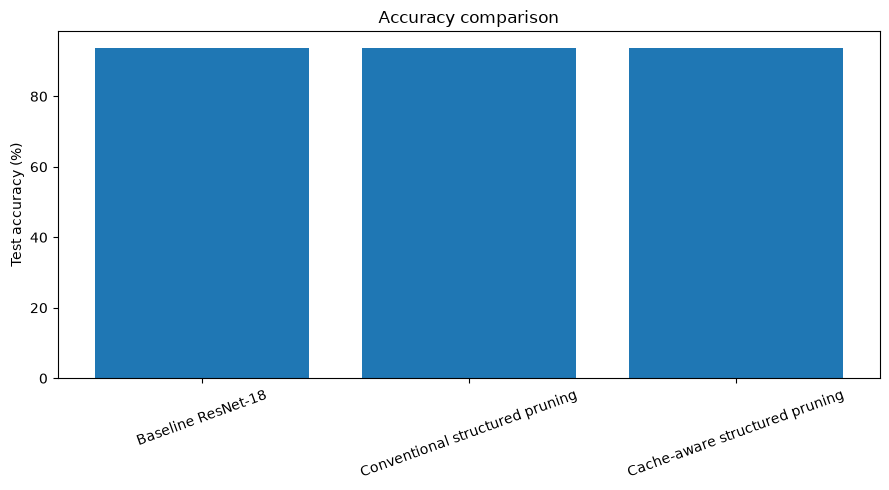

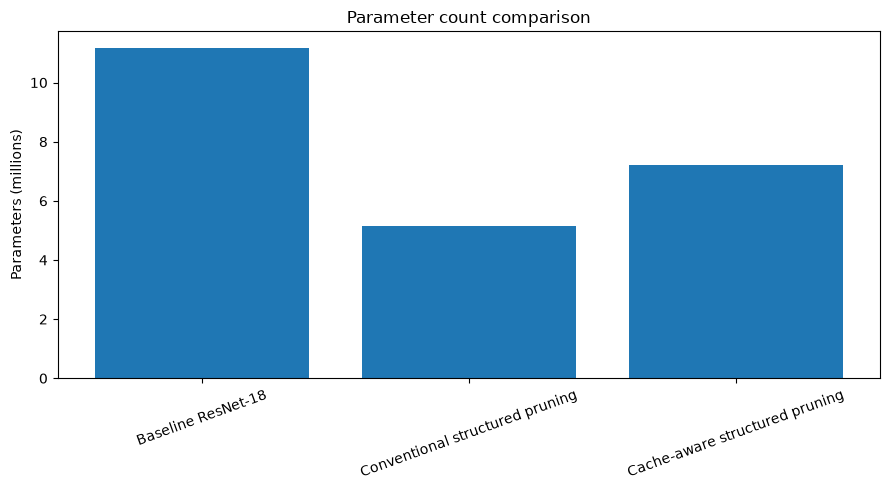

In [67]:

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["test_accuracy_percent"],
)

ax.set_ylabel("Test accuracy (%)")
ax.set_title("Accuracy comparison")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["parameters"] / 1e6,
)

ax.set_ylabel("Parameters (millions)")
ax.set_title("Parameter count comparison")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


## 33. Plot latency, GPU power and measured energy

**What happens in this cell:**  
Plots the hardware measurements that matter for the energy-efficiency objective.

If NVML was unavailable, the energy plot will contain missing values rather than fabricated numbers.

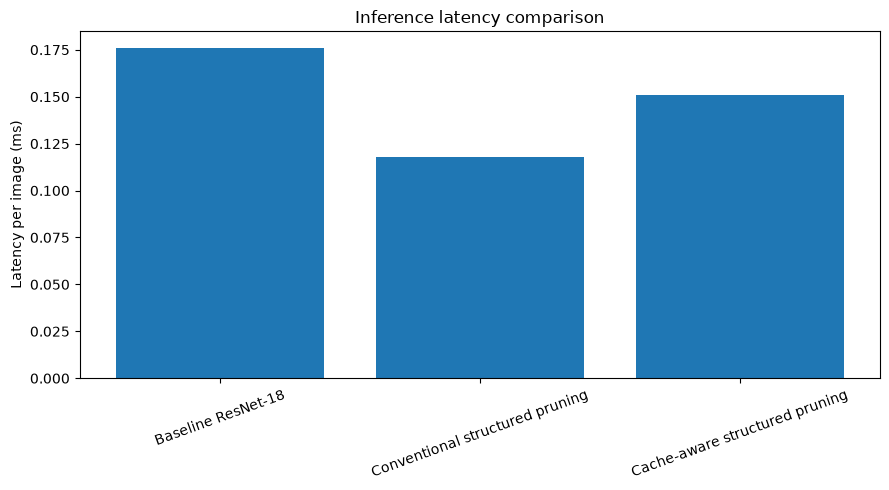

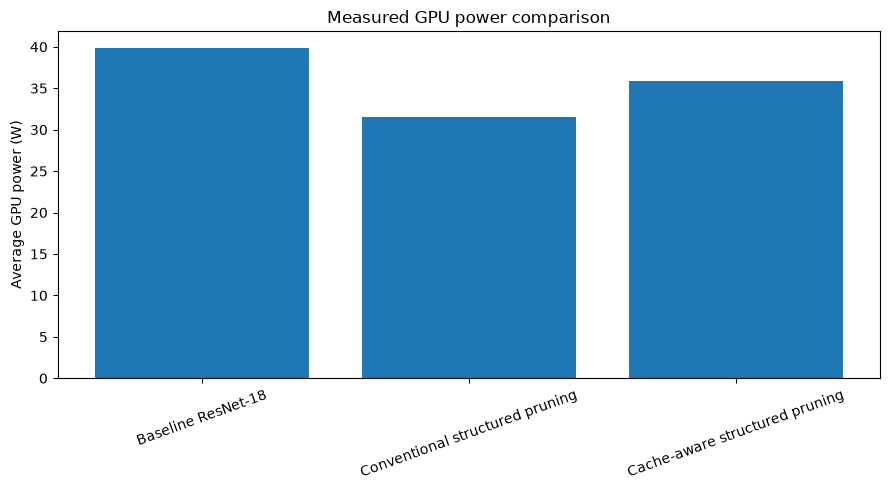

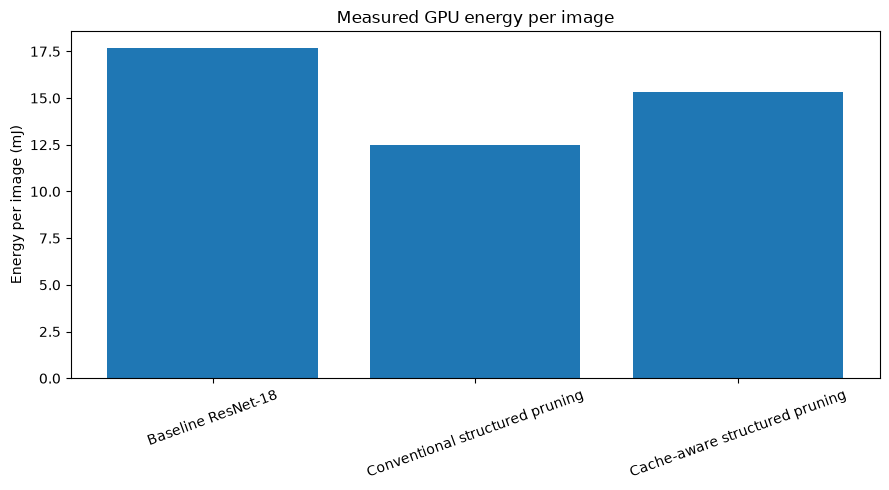

In [68]:

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["latency_image_ms"],
)

ax.set_ylabel("Latency per image (ms)")
ax.set_title("Inference latency comparison")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["avg_gpu_power_w"],
)

ax.set_ylabel("Average GPU power (W)")
ax.set_title("Measured GPU power comparison")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["model"],
    comparison["energy_per_image_mj"],
)

ax.set_ylabel("Energy per image (mJ)")
ax.set_title("Measured GPU energy per image")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


## 34. Plot the cache-aware layer policy

**What happens in this cell:**  
Visualizes which convolutional layers received more pruning pressure from the cache-aware policy.

This plot is useful when explaining the research contribution to a supervisor.

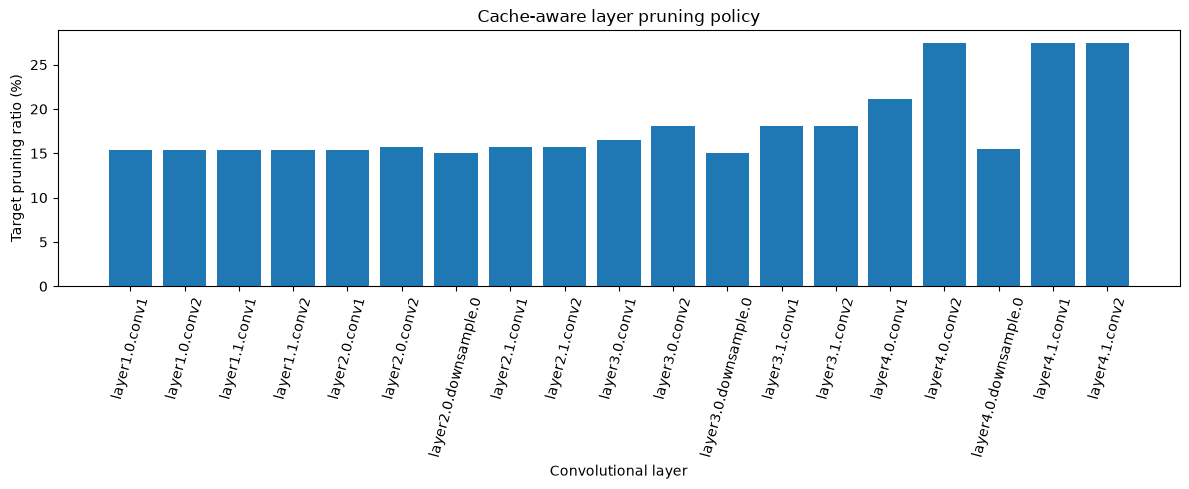

In [69]:

policy_plot = policy_df.copy()

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    policy_plot["layer"],
    policy_plot["target_pruning_ratio"] * 100,
)

ax.set_ylabel("Target pruning ratio (%)")
ax.set_xlabel("Convolutional layer")
ax.set_title("Cache-aware layer pruning policy")
ax.tick_params(axis="x", rotation=75)

plt.tight_layout()
plt.show()


## 35. Save all experiment metadata

**What happens in this cell:**  
Stores the configuration, GPU name and cache assumptions so the experiment can be reproduced later.

In [70]:

metadata = {
    "seed": SEED,
    "smoke_test": SMOKE_TEST,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "baseline_epochs": BASELINE_EPOCHS,
    "finetune_epochs": FINETUNE_EPOCHS,
    "conventional_pruning_ratio": CONVENTIONAL_PRUNING_RATIO,
    "cache_aware_max_ratio": CACHE_AWARE_MAX_RATIO,
    "round_to": ROUND_TO,
    "device": str(DEVICE),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if DEVICE.type == "cuda"
        else "CPU"
    ),
    "nvml_available": NVML_OK,
    "l2_cache_mb": L2_CACHE_MB,
    "l2_cache_source": L2_SOURCE,
    "cifar_raw_root": str(RAW_ROOT),
    "memmap_root": str(MEMMAP_ROOT),
}

with open(
    RESULT_ROOT / "experiment_metadata.json",
    "w"
) as f:
    json.dump(
        metadata,
        f,
        indent=2,
    )

print(json.dumps(metadata, indent=2))


{
  "seed": 42,
  "smoke_test": false,
  "batch_size": 128,
  "num_workers": 0,
  "baseline_epochs": 50,
  "finetune_epochs": 20,
  "conventional_pruning_ratio": 0.3,
  "cache_aware_max_ratio": 0.4,
  "round_to": 8,
  "device": "cuda",
  "gpu_name": "NVIDIA GeForce RTX 4050 Laptop GPU",
  "nvml_available": true,
  "l2_cache_mb": 24.0,
  "l2_cache_source": "PyTorch property: L2_cache_size",
  "cifar_raw_root": "/home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar-10-batches-py",
  "memmap_root": "/home/komal-sai-jakka/ACADEMICS/5th_sem/machine_learning/research/data/cifar10_memmap"
}


## 36. Final research checklist

### What has been measured?

- Baseline ResNet-18 accuracy
- Conventional structured-pruning accuracy
- Cache-aware structured-pruning accuracy
- Parameter counts
- Model sizes
- FLOPs/MAC-related computation
- Inference latency
- Peak GPU memory
- Average GPU power
- Energy per image, when NVML is available

### What is the proposed contribution?

The cache-aware method uses:

**filter importance + estimated working-set/cache pressure**

to determine where pruning pressure should be applied.

### Important scientific limitation

The cache analysis in this notebook is an **analytical working-set estimate**. It is not direct evidence of L2 cache hit/miss rates.

For the final thesis/paper, use NVIDIA Nsight Compute or another hardware-counter profiler to validate:

- L2 hit rate
- L2 misses
- DRAM traffic
- achieved memory bandwidth
- kernel execution time

The current notebook gives you the complete end-to-end pruning and measured GPU-energy experiment; hardware-counter profiling can then be added as a separate validation stage.

### Main output files

`results/final_three_way_comparison.csv`

`results/baseline_metrics.csv`

`results/baseline_history.csv`

`results/conventional_pruned_history.csv`

`results/cache_aware_history.csv`

`results/baseline_cache_working_sets.csv`

`results/cache_aware_layer_policy.csv`

`results/experiment_metadata.json`

### Recommended execution order

1. Run cells 1–10.
2. Confirm CIFAR-10 is detected and the memory-mapped files are created.
3. Run cells 11–16.
4. Check that baseline training works and NVML reports GPU power.
5. Run cells 17–22.
6. Run cells 23–30 for the cache-aware experiment.
7. Run cells 31–36 for the final comparison and plots.

For the first successful run, keep `SMOKE_TEST=True`. After the complete pipeline succeeds, change it to `False` and repeat the experiment with the full epoch counts.